# Assignment 1: Data Profiling (EDA) Report
## Olist E-commerce Order and Delivery Data Quality

**Course:** Data Engineering  
**Team members and matric numbers:**

| Name | Matric Number |
|---|---|
| LI ZEHAO | A207409 |
| WU ZHUXI | A207359 |
| LYU HAOWEN | A206795 |
| HAN HAOZHENG | A207411 |

## 1. Scenario (2–3 sentences)

Olist is a Brazilian e-commerce platform with data about orders, items, and customers. This data may have missing delivery dates, unusual prices, and other quality problems. We want to check these problems and prepare reliable data for our future e-commerce delivery analysis.

**Questions for this report:** Which columns have missing values? Are there possible price or freight outliers? Are the IDs, dates, and customer locations consistent enough for later data engineering work?

## 2. Data source and how we obtained it

- **Original dataset:** [Brazilian E-Commerce Public Dataset by Olist — Kaggle](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce)
- **Public CSV copy hosted by Olist:** [Olist GitHub / work-at-olist-data / datasets](https://github.com/olist/work-at-olist-data/tree/master/datasets)
- **Files used:** `olist_orders_dataset.csv`, `olist_order_items_dataset.csv`, and `olist_customers_dataset.csv`.
- **How it was obtained:** The code below downloads these CSV files from Olist's public GitHub repository if they are not already in `data/raw/`, then reads them using `pandas.read_csv()`.
- **Why three tables?** Orders contain delivery dates, items contain prices and freight values, and customers contain location information. These are enough to check data quality for the capstone delivery scenario.

In [1]:
from pathlib import Path
from urllib.request import Request, urlopen
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_columns', 30)
BASE = Path.cwd()
RAW_DIR = BASE / 'data' / 'raw'
CLEAN_DIR = BASE / 'data' / 'processed'
RAW_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_DIR.mkdir(parents=True, exist_ok=True)

FILES = {
    'orders': 'olist_orders_dataset.csv',
    'items': 'olist_order_items_dataset.csv',
    'customers': 'olist_customers_dataset.csv',
}
URL_BASE = 'https://raw.githubusercontent.com/olist/work-at-olist-data/master/datasets/'

for file_name in FILES.values():
    target = RAW_DIR / file_name
    if not target.exists():
        url = URL_BASE + file_name
        print(f'Downloading {file_name} ...')
        try:
            request = Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            with urlopen(request, timeout=90) as response, open(target, 'wb') as file_out:
                shutil.copyfileobj(response, file_out)
        except Exception as exc:
            target.unlink(missing_ok=True)
            raise RuntimeError(
                f'Could not download {file_name}. Download it from the Kaggle link '
                f'and put it in {RAW_DIR}, then run the notebook again.'
            ) from exc
    print(f'Found: {file_name}')

Found: olist_orders_dataset.csv
Found: olist_order_items_dataset.csv
Found: olist_customers_dataset.csv


In [2]:
orders = pd.read_csv(
    RAW_DIR / FILES['orders'],
    dtype={'order_id': 'string', 'customer_id': 'string'}
)
items = pd.read_csv(
    RAW_DIR / FILES['items'],
    dtype={'order_id': 'string', 'product_id': 'string', 'seller_id': 'string'}
)
customers = pd.read_csv(
    RAW_DIR / FILES['customers'],
    dtype={
        'customer_id': 'string',
        'customer_unique_id': 'string',
        'customer_zip_code_prefix': 'string',
        'customer_city': 'string',
        'customer_state': 'string'
    }
)
raw_tables = {'Orders': orders, 'Order items': items, 'Customers': customers}
shape_report = pd.DataFrame([
    {'Table': name, 'Rows': len(df), 'Columns': len(df.columns)}
    for name, df in raw_tables.items()
])
display(shape_report)
print('Columns in each table:')
for name, df in raw_tables.items():
    print(f'{name}: {list(df.columns)}')

,Table,Rows,Columns
0,Orders,99441,8
1,Order items,112650,7
2,Customers,99441,5


Columns in each table:
Orders: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
Order items: ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']
Customers: ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']


## 3. Data profiling and issue handling

### 3.1 Missing values

First, we count missing values in all three tables. A missing date is not always a mistake: a cancelled or unfinished order may have no delivery date. We should not invent a delivery date.

In [3]:
missing_parts = []
for table_name, df in raw_tables.items():
    part = pd.DataFrame({
        'Table': table_name,
        'Column': df.columns,
        'Missing count': df.isna().sum().values,
        'Missing %': (df.isna().mean().values * 100).round(2)
    })
    missing_parts.append(part)
missing_report = pd.concat(missing_parts, ignore_index=True)
display(missing_report.sort_values(['Missing count', 'Table'], ascending=[False, True]).reset_index(drop=True))

,Table,Column,Missing count,Missing %
0,Orders,order_delivered_customer_date,2965,2.98
1,Orders,order_delivered_carrier_date,1783,1.79
2,Orders,order_approved_at,160,0.16
3,Customers,customer_id,0,0.00
4,Customers,customer_unique_id,0,0.00
5,Customers,customer_zip_code_prefix,0,0.00
6,Customers,customer_city,0,0.00
7,Customers,customer_state,0,0.00
8,Order items,order_id,0,0.00
9,Order items,order_item_id,0,0.00


**Decision:** We keep missing dates in the original orders. For delivery-time calculations, we later use only delivered orders that have the required real dates. We do not use the mean or median to fill delivery timestamps, because this would create false delivery information. If any required date is missing, that order is excluded only from the delivery-ready subset, not deleted from the full cleaned order table.

### 3.2 Duplicate records and primary keys

We check both exact duplicate rows and duplicate business keys. The main keys are `order_id` for orders, `customer_id` for customers, and (`order_id`, `order_item_id`) for order items. A single order can contain more than one item, so a repeated `order_id` in the **items** table is not automatically a duplicate.

In [4]:
item_keys = ['order_id', 'order_item_id']
key_report = pd.DataFrame([
    {'Table': 'Orders', 'Exact duplicate rows': int(orders.duplicated().sum()),
     'Rows with a repeated key': int(orders.duplicated('order_id', keep=False).sum())},
    {'Table': 'Order items', 'Exact duplicate rows': int(items.duplicated().sum()),
     'Rows with a repeated key': int(items.duplicated(item_keys, keep=False).sum())},
    {'Table': 'Customers', 'Exact duplicate rows': int(customers.duplicated().sum()),
     'Rows with a repeated key': int(customers.duplicated('customer_id', keep=False).sum())},
])
display(key_report)

,Table,Exact duplicate rows,Rows with a repeated key
0,Orders,0,0
1,Order items,0,0
2,Customers,0,0


**Decision:** Remove exact duplicate rows, because they add no new information. If a key still points to different records, flag all conflicting key rows and keep them out of the cleaned tables for manual review. We do not choose a random record.

### 3.3 Wrong data types, invalid values, and inconsistent formats

We convert the order dates to `datetime`, numeric amounts to numbers, and state names to uppercase. ZIP code prefixes are read as strings so that leading zeros are not lost. We also check invalid status labels, negative prices, and IDs that do not match between tables.

In [5]:
# Work on copies. The original dataframes remain unchanged for comparison.
orders_clean = orders.drop_duplicates().copy()
items_clean = items.drop_duplicates().copy()
customers_clean = customers.drop_duplicates().copy()

# Quarantine all conflicting primary-key rows instead of selecting one randomly.
conflict_orders = orders_clean['order_id'].duplicated(keep=False)
conflict_items = items_clean.duplicated(['order_id', 'order_item_id'], keep=False)
conflict_customers = customers_clean['customer_id'].duplicated(keep=False)

flagged_order_keys = orders_clean.loc[conflict_orders].copy()
flagged_item_keys = items_clean.loc[conflict_items].copy()
flagged_customer_keys = customers_clean.loc[conflict_customers].copy()

orders_clean = orders_clean.loc[~conflict_orders & orders_clean['order_id'].notna()].copy()
items_clean = items_clean.loc[~conflict_items].copy()
customers_clean = customers_clean.loc[
    ~conflict_customers & customers_clean['customer_id'].notna()
].copy()

# Normalize order status and parse dates.
orders_clean['order_status'] = orders_clean['order_status'].astype('string').str.strip().str.lower()
valid_statuses = {'created', 'approved', 'invoiced', 'processing', 'shipped',
                  'delivered', 'canceled', 'unavailable'}
orders_clean['unknown_status_flag'] = ~orders_clean['order_status'].isin(valid_statuses).fillna(False)

DATE_COLS = [
    'order_purchase_timestamp', 'order_approved_at',
    'order_delivered_carrier_date', 'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
invalid_date_counts = {}
for col in DATE_COLS:
    original_nonempty = orders_clean[col].notna() & orders_clean[col].astype('string').str.strip().ne('')
    parsed = pd.to_datetime(orders_clean[col], errors='coerce')
    invalid_date_counts[col] = int((original_nonempty & parsed.isna()).sum())
    orders_clean[col] = parsed

# Read order-item IDs and prices as numeric values.
items_clean['order_item_id'] = pd.to_numeric(items_clean['order_item_id'], errors='coerce')
items_clean['price'] = pd.to_numeric(items_clean['price'], errors='coerce')
items_clean['freight_value'] = pd.to_numeric(items_clean['freight_value'], errors='coerce')
invalid_item_values = (
    items_clean['order_id'].isna() |
    items_clean['order_item_id'].isna() |
    (items_clean['order_item_id'] <= 0) |
    (items_clean['order_item_id'] % 1 != 0) |
    items_clean['price'].isna() | (items_clean['price'] <= 0) |
    items_clean['freight_value'].isna() | (items_clean['freight_value'] < 0)
)
flagged_item_values = items_clean.loc[invalid_item_values].copy()
items_clean = items_clean.loc[~invalid_item_values].copy()
items_clean['order_item_id'] = items_clean['order_item_id'].astype('int64')

# Normalize location strings. Keep ZIP codes as text and flag invalid ones.
customers_clean['customer_state'] = customers_clean['customer_state'].astype('string').str.strip().str.upper()
customers_clean['customer_city'] = customers_clean['customer_city'].astype('string').str.strip().str.lower()
zip_original = customers_clean['customer_zip_code_prefix'].astype('string').str.strip()
zip_format_ok = zip_original.str.fullmatch(r'\d{1,5}').fillna(False)
customers_clean['invalid_zip_flag'] = ~zip_format_ok
customers_clean['customer_zip_code_prefix'] = zip_original.where(~zip_format_ok, zip_original.str.zfill(5))

# Check foreign keys. Do not invent unknown customers or orders.
missing_customer_link = ~orders_clean['customer_id'].isin(customers_clean['customer_id'])
missing_order_link = ~items_clean['order_id'].isin(orders_clean['order_id'])
flagged_orphan_items = items_clean.loc[missing_order_link].copy()
items_clean = items_clean.loc[~missing_order_link].copy()

quality_report = pd.DataFrame([
    {'Check': 'Unresolved conflicting order IDs', 'Count': len(flagged_order_keys)},
    {'Check': 'Unresolved conflicting item keys', 'Count': len(flagged_item_keys)},
    {'Check': 'Unresolved conflicting customer IDs', 'Count': len(flagged_customer_keys)},
    {'Check': 'Unknown order statuses (flagged)', 'Count': int(orders_clean['unknown_status_flag'].sum())},
    {'Check': 'Unparseable non-empty dates (flagged as missing)', 'Count': sum(invalid_date_counts.values())},
    {'Check': 'Invalid item numbers or money values (excluded)', 'Count': len(flagged_item_values)},
    {'Check': 'Items without a matching order (excluded)', 'Count': len(flagged_orphan_items)},
    {'Check': 'Orders without a matching customer (flagged)', 'Count': int(missing_customer_link.sum())},
    {'Check': 'Invalid customer ZIP prefix (flagged)', 'Count': int(customers_clean['invalid_zip_flag'].sum())},
])
display(quality_report)
print('Invalid date counts by column:', invalid_date_counts)

,Check,Count
0,Unresolved conflicting order IDs,0
1,Unresolved conflicting item keys,0
2,Unresolved conflicting customer IDs,0
3,Unknown order statuses (flagged),0
4,Unparseable non-empty dates (flagged as missing),0
5,Invalid item numbers or money values (excluded),0
6,Items without a matching order (excluded),0
7,Orders without a matching customer (flagged),0
8,Invalid customer ZIP prefix (flagged),0


Invalid date counts by column: {'order_purchase_timestamp': 0, 'order_approved_at': 0, 'order_delivered_carrier_date': 0, 'order_delivered_customer_date': 0, 'order_estimated_delivery_date': 0}


**Decision:** We remove invalid amounts from the item-analysis table, but we keep the original rows available in `data/raw/`. Unknown statuses, invalid ZIP prefixes, and date parsing problems are flagged, not silently changed. The recorded issue counts above show whether each problem actually occurs.

### 3.4 Outliers (IQR method)

We check outliers in `price` and `freight_value` using the **interquartile range (IQR)**:

- `IQR = Q3 - Q1`
- Lower limit: `Q1 - 1.5 × IQR`
- Upper limit: `Q3 + 1.5 × IQR`

A very high price can be a genuine expensive item, and high freight may be genuine long-distance delivery. We keep positive outliers and add flags instead of deleting or capping them without evidence.

In [6]:
def iqr_check(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return lower, upper, (series < lower) | (series > upper)

price_lower, price_upper, price_outlier = iqr_check(items_clean['price'])
freight_lower, freight_upper, freight_outlier = iqr_check(items_clean['freight_value'])
items_clean['price_outlier_flag'] = price_outlier
items_clean['freight_outlier_flag'] = freight_outlier
outlier_report = pd.DataFrame([
    {'Column': 'price', 'Lower IQR limit': price_lower, 'Upper IQR limit': price_upper,
     'Outlier rows': int(price_outlier.sum()),
     'Outlier %': round(100 * price_outlier.mean(), 2), 'Action': 'Keep and flag'},
    {'Column': 'freight_value', 'Lower IQR limit': freight_lower, 'Upper IQR limit': freight_upper,
     'Outlier rows': int(freight_outlier.sum()),
     'Outlier %': round(100 * freight_outlier.mean(), 2), 'Action': 'Keep and flag'},
])
display(outlier_report.round(2))

,Column,Lower IQR limit,Upper IQR limit,Outlier rows,Outlier %,Action
0,price,-102.60,277.40,8427,7.48,Keep and flag
1,freight_value,0.98,33.25,12180,10.81,Keep and flag


## 4. Diagnostic charts

These charts are made to find data problems, not to present business results. Each chart has a title and labels.

### Chart 1 — Missing values in the original orders table

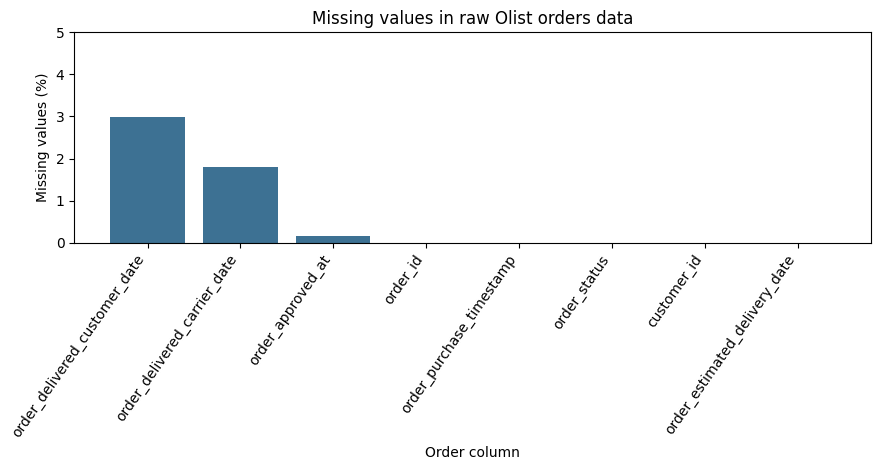

Interpretation: Some date fields may be empty because an order was not delivered yet. We keep the missing dates rather than replacing them with invented dates.


In [7]:
order_missing = (orders.isna().mean() * 100).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.bar(order_missing.index, order_missing.values, color='#3D7193')
ax.set_title('Missing values in raw Olist orders data')
ax.set_ylabel('Missing values (%)')
ax.set_xlabel('Order column')
ax.tick_params(axis='x', rotation=55)
for label in ax.get_xticklabels():
    label.set_ha('right')
ax.set_ylim(0, max(5, float(order_missing.max()) * 1.17))
fig.tight_layout()
plt.show()
print('Interpretation: Some date fields may be empty because an order was not delivered yet. '
      'We keep the missing dates rather than replacing them with invented dates.')

### Chart 2 — Unusual prices and freight values

The boxplots use a logarithmic scale for positive values so that large amounts are easier to see. The plots show why we should inspect possible outliers, not automatically remove them.

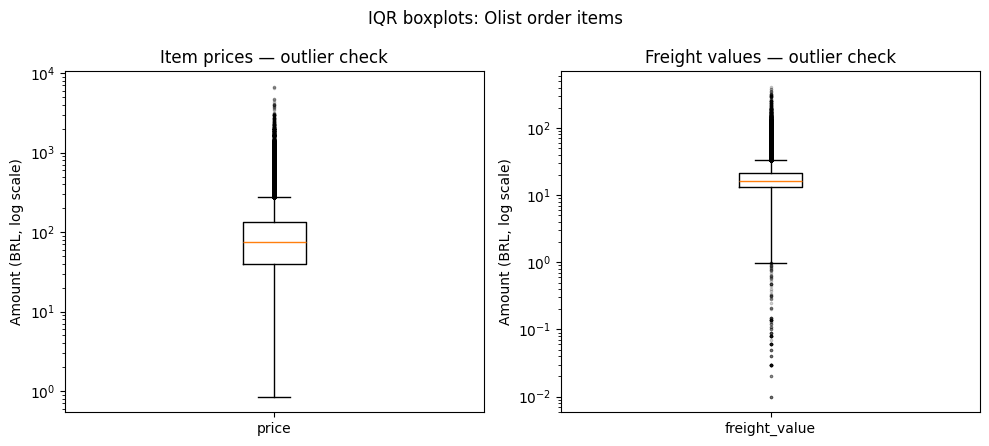

Interpretation: Values outside the IQR whiskers need review. We keep valid, non-negative high amounts and label them as potential outliers.


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, col, title in zip(axes, ['price', 'freight_value'],
                          ['Item prices', 'Freight values']):
    positive = items_clean.loc[items_clean[col] > 0, col]
    if not positive.empty:
        ax.boxplot(positive.to_numpy(), vert=True,
                   flierprops={'marker': '.', 'markersize': 3, 'alpha': 0.25})
        ax.set_xticks([1], [col])
        ax.set_yscale('log')
    ax.set_ylabel('Amount (BRL, log scale)')
    ax.set_title(title + ' — outlier check')
fig.suptitle('IQR boxplots: Olist order items')
fig.tight_layout()
plt.show()
print('Interpretation: Values outside the IQR whiskers need review. '
      'We keep valid, non-negative high amounts and label them as potential outliers.')

### Chart 3 — Group balance by customer state

We check whether customer records are distributed evenly across states. Unequal counts may mean that some areas are not well represented in this dataset. This is a sampling/coverage check, not proof of unfair treatment.

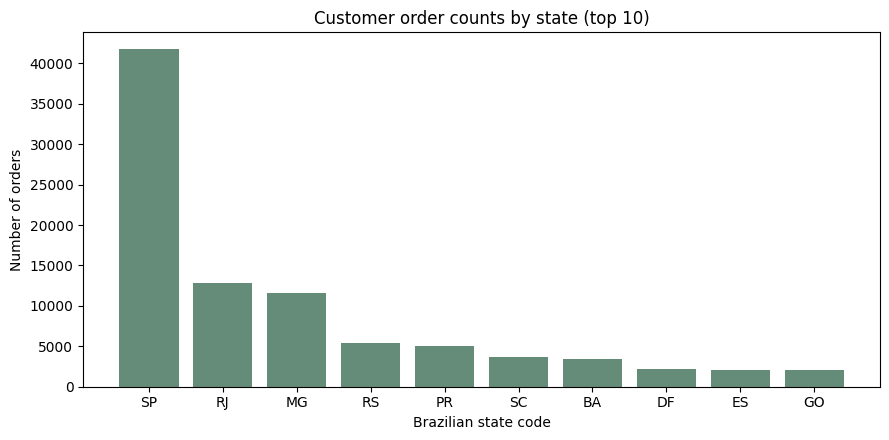

Top state: SP has 41,746 orders (42.0% of orders with a known state).
Interpretation: States have different numbers of orders, so findings may not represent every region equally. Missing customer links are excluded only from this chart.


In [9]:
order_states = orders_clean[['order_id', 'customer_id']].merge(
    customers_clean[['customer_id', 'customer_state']],
    how='left', on='customer_id', validate='many_to_one'
)
state_counts = order_states['customer_state'].dropna().value_counts()
fig, ax = plt.subplots(figsize=(9, 4.5))
if len(state_counts):
    ax.bar(state_counts.head(10).index, state_counts.head(10).values, color='#658C78')
else:
    ax.text(0.5, 0.5, 'No state data available', ha='center', va='center', transform=ax.transAxes)
ax.set_title('Customer order counts by state (top 10)')
ax.set_xlabel('Brazilian state code')
ax.set_ylabel('Number of orders')
fig.tight_layout()
plt.show()
if len(state_counts):
    print(f'Top state: {state_counts.index[0]} has {state_counts.iloc[0]:,} orders '
          f'({state_counts.iloc[0] / state_counts.sum() * 100:.1f}% of orders with a known state).')
print('Interpretation: States have different numbers of orders, so findings may not '
      'represent every region equally. Missing customer links are excluded only from this chart.')

## 5. Personally identifiable information (PII) and bias risks

**Privacy:** Olist says this public dataset has been anonymised. The `customer_id` and `customer_unique_id` are pseudonymous identifiers, not names. However, IDs combined with ZIP-code prefixes, city, or state can still create re-identification or linkage risk. We should avoid uploading row-level customer records or publishing IDs. We use only state-level counts in the public chart and exclude raw and cleaned CSVs from GitHub.

**Possible bias:** Some states have more orders than others. Olist data contains orders from participating marketplace channels in 2016–2018, so it may not represent every Brazilian customer or present-day shopping behaviour. We report group sizes and avoid making claims about all regions. The data has no reliable demographic labels here, so we cannot test demographic fairness from these three tables.

**Handling plan:** Keep sensitive raw data in local folders, limit access, use aggregated charts, and describe coverage limitations before using the data for decisions.

## 6. Final checks and conclusion

For a delivery-time dataset, we only use delivered orders with both a real purchase date and a real delivery date. Orders with a delivery date before their purchase date are flagged as inconsistent and excluded from this specific subset. All other cleaned order records are still available for other analyses.

In [10]:
orders_clean['missing_actual_delivery_flag'] = (
    orders_clean['order_status'].eq('delivered') &
    orders_clean['order_delivered_customer_date'].isna()
)
orders_clean['negative_delivery_time_flag'] = (
    orders_clean['order_delivered_customer_date'].notna() &
    orders_clean['order_purchase_timestamp'].notna() &
    (orders_clean['order_delivered_customer_date'] < orders_clean['order_purchase_timestamp'])
)
usable_delivery = (
    orders_clean['order_status'].eq('delivered') &
    orders_clean['order_purchase_timestamp'].notna() &
    orders_clean['order_delivered_customer_date'].notna() &
    orders_clean['order_estimated_delivery_date'].notna() &
    ~orders_clean['negative_delivery_time_flag'] &
    ~orders_clean['unknown_status_flag']
)
delivery_ready = orders_clean.loc[usable_delivery].copy()
delivery_ready['delivery_days'] = (
    delivery_ready['order_delivered_customer_date'] -
    delivery_ready['order_purchase_timestamp']
).dt.total_seconds() / (24 * 60 * 60)

assert orders_clean['order_id'].is_unique
assert customers_clean['customer_id'].is_unique
assert not items_clean.duplicated(['order_id', 'order_item_id']).any()
assert (items_clean['price'] > 0).all()
assert (items_clean['freight_value'] >= 0).all()
assert (delivery_ready['delivery_days'] >= 0).all()

final_report = pd.DataFrame([
    {'Dataset': 'Orders', 'Raw rows': len(orders), 'Cleaned rows': len(orders_clean)},
    {'Dataset': 'Order items', 'Raw rows': len(items), 'Cleaned rows': len(items_clean)},
    {'Dataset': 'Customers', 'Raw rows': len(customers), 'Cleaned rows': len(customers_clean)},
    {'Dataset': 'Delivery-ready subset', 'Raw rows': len(orders), 'Cleaned rows': len(delivery_ready)},
])
display(final_report)
print(f'Orders marked delivered but missing actual delivery date: '
      f'{int(orders_clean["missing_actual_delivery_flag"].sum()):,}')
print(f'Orders with delivery before purchase: '
      f'{int(orders_clean["negative_delivery_time_flag"].sum()):,}')
print(f'Delivery-ready orders: {len(delivery_ready):,} / {len(orders):,} '
      f'({100 * len(delivery_ready) / len(orders):.1f}% of raw orders)')

,Dataset,Raw rows,Cleaned rows
0,Orders,99441,99441
1,Order items,112650,112650
2,Customers,99441,99441
3,Delivery-ready subset,99441,96470


Orders marked delivered but missing actual delivery date: 8
Orders with delivery before purchase: 0
Delivery-ready orders: 96,470 / 99,441 (97.0% of raw orders)


**Conclusion:**

The Olist data is useful for our delivery data engineering project, but it needs cleaning before analysis. We checked missing dates, duplicates, invalid data, unusual prices, and customer location coverage. We kept possible valid outliers and did not make up missing delivery dates. We also created a smaller delivery-ready dataset using real dates only.

**Remaining limitations:**

The data covers 2016–2018 and may not represent current sales. Some orders do not have delivery dates, customer locations may be incomplete, and the state distribution is uneven. The available columns also do not allow us to test demographic fairness. Future capstone work can connect more Olist tables, but that is outside the scope of this Assignment 1.

### Optional: save local cleaned files for the later capstone

These output files go into `data/processed/`. They are not included in the GitHub upload, because `.gitignore` excludes the data folders. You only need to submit the GitHub repository link containing this notebook, README and run instructions.

In [11]:
orders_clean.to_csv(CLEAN_DIR / 'olist_orders_clean.csv', index=False)
items_clean.to_csv(CLEAN_DIR / 'olist_order_items_clean.csv', index=False)
customers_clean.to_csv(CLEAN_DIR / 'olist_customers_clean.csv', index=False)
delivery_ready.to_csv(CLEAN_DIR / 'olist_delivery_ready.csv', index=False)
print('Finished. Four cleaned CSV files saved locally in:', CLEAN_DIR)
print('For GitHub, upload the notebook, README.md, requirements.txt and .gitignore. Do not upload data/raw or data/processed CSV files.')

Finished. Four cleaned CSV files saved locally in: /content/data/processed
For GitHub, upload the notebook, README.md, requirements.txt and .gitignore. Do not upload data/raw or data/processed CSV files.
